# Segmenter les clients d'Olist pour cibler les campagnes marketing
## Partie 1 : Analyse exploratoire et préparation des données RFM

### Sommaire <a class="anchor" id="sommaire"></a>

* [Analyse exploratoire](#00)
    * [Introduction](#0)
    * [Les clients : identifiant, ville, État, code postal, localisation](#1)
    * [Les commandes](#2)
    * [Les produits commandés](#3)
    * [Les paiements](#4)
    * [Les avis des clients](#5)
    * [Les vendeurs](#6)
* [Construction du fichier RFM](#7)
* [Conclusion](#8)

# Analyse exploratoire<a class="anchor" id="00"></a>

## Introduction<a class="anchor" id="0"></a>

**Olist** est une marketplace brésilienne qui met en relation des vendeurs et des clients. L'entreprise souhaite **regrouper ses clients en profils similaires** pour adapter ses campagnes marketing. Elle demande aussi une recommandation sur la **fréquence de mise à jour** de cette segmentation (contrat de maintenance).

Ce premier notebook :
- **explore** les 9 fichiers fournis par Olist (clients, commandes, produits, paiements, avis, vendeurs) ;
- **construit**, pour chaque client, les variables **RFM** : **R**écence (temps écoulé depuis la dernière commande), **F**réquence (nombre de commandes) et **M**ontant (total dépensé).

Ces variables serviront ensuite à segmenter les clients avec des **méthodes non supervisées** (clustering), dans le notebook 2.

### Chargement des données

In [1]:
# Bibliothèque standard
import os

# Manipulation des données
import pandas as pd
import numpy as np

# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Style commun à tous les graphiques
sns.set_theme(style="whitegrid", palette="bright")

In [2]:
# Les données Olist sont à télécharger sur Kaggle (lien dans le README)
# et à placer dans un dossier data/ à côté de ce notebook
path = 'data/'

# Liste des fichiers disponibles
folder = os.listdir(path)
folder

['data_commandes.csv',
 'olist_customers_dataset.csv',
 'olist_geolocation_dataset.csv',
 'olist_orders_dataset.csv',
 'olist_order_items_dataset.csv',
 'olist_order_payments_dataset.csv',
 'olist_order_reviews_dataset.csv',
 'olist_products_dataset.csv',
 'olist_sellers_dataset.csv',
 'product_category_name_translation.csv',
 'rfm.csv']

In [3]:
# Lecture des 9 fichiers CSV fournis par Olist
olist_customers_dataset = pd.read_csv(path + "olist_customers_dataset.csv")
olist_geolocation_dataset = pd.read_csv(path + "olist_geolocation_dataset.csv")
olist_orders_dataset = pd.read_csv(path + "olist_orders_dataset.csv")
olist_order_items_dataset = pd.read_csv(path + "olist_order_items_dataset.csv")
olist_order_payments_dataset = pd.read_csv(path + "olist_order_payments_dataset.csv")
olist_order_reviews_dataset = pd.read_csv(path + "olist_order_reviews_dataset.csv")
olist_products_dataset = pd.read_csv(path + "olist_products_dataset.csv")
olist_sellers_dataset = pd.read_csv(path + "olist_sellers_dataset.csv")
product_category_name_translation = pd.read_csv(path + "product_category_name_translation.csv")

In [4]:
# Dimensions de chaque fichier
tables = {
    "Clients": olist_customers_dataset,
    "Géolocalisation": olist_geolocation_dataset,
    "Commandes": olist_orders_dataset,
    "Produits commandés": olist_order_items_dataset,
    "Paiements": olist_order_payments_dataset,
    "Avis": olist_order_reviews_dataset,
    "Produits": olist_products_dataset,
    "Vendeurs": olist_sellers_dataset,
    "Traduction des catégories": product_category_name_translation,
}

for nom, df in tables.items():
    print(f"* {nom} : {df.shape[0]:,} lignes, {df.shape[1]} colonnes")

* Clients : 99,441 lignes, 5 colonnes
* Géolocalisation : 1,000,163 lignes, 5 colonnes
* Commandes : 99,441 lignes, 8 colonnes
* Produits commandés : 112,650 lignes, 7 colonnes
* Paiements : 103,886 lignes, 5 colonnes
* Avis : 99,224 lignes, 7 colonnes
* Produits : 32,951 lignes, 9 colonnes
* Vendeurs : 3,095 lignes, 4 colonnes
* Traduction des catégories : 71 lignes, 2 colonnes


Les **9 fichiers** fournis par Olist sont reliés entre eux par des **clés** : des colonnes communes qui permettent de les fusionner. Par exemple, `order_id` relie les commandes à leurs paiements, leurs produits et leurs avis.

<img src="images/schema_donnees_olist.png" alt="Schéma des données Olist" width="700">

<a href="#sommaire" rev="footnote">&#8617;</a>

## Les clients : identifiant, ville, État, code postal, localisation <a class="anchor" id="1"></a>

### Le fichier des clients (`olist_customers_dataset`)

Chaque ligne correspond à un client **pour une commande donnée**. Le fichier contient deux identifiants :
- `customer_id` : un identifiant différent **à chaque commande** ;
- `customer_unique_id` : l'identifiant **unique de la personne**. C'est lui qui permettra de compter le nombre de commandes par client (la fréquence du RFM).

In [5]:
# Copie de travail pour ne pas modifier les données d'origine
df_customers = olist_customers_dataset.copy()
df_customers.head()

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


In [6]:
print(f"Le fichier contient {df_customers.shape[0]:,} lignes et {df_customers.shape[1]} colonnes.")
print(f"Nombre de clients uniques : {df_customers['customer_unique_id'].nunique():,}")

Le fichier contient 99,441 lignes et 5 colonnes.
Nombre de clients uniques : 96,096


In [7]:
# Le code postal est une variable qualitative : on compte les valeurs distinctes plutôt que de calculer une moyenne
print(f"Codes postaux différents : {df_customers['customer_zip_code_prefix'].nunique():,}")
print(f"Villes différentes : {df_customers['customer_city'].nunique():,}")
print(f"États différents : {df_customers['customer_state'].nunique()}")

Codes postaux différents : 14,994
Villes différentes : 4,119
États différents : 27


### Le fichier de géolocalisation (`olist_geolocation_dataset`)

Ce fichier associe chaque **code postal** à des **coordonnées GPS** (latitude, longitude). Il servira à placer les clients sur une carte.
Un même code postal y apparaît **plusieurs fois**, avec des coordonnées légèrement différentes : il faudra donc supprimer ces doublons avant de le fusionner avec le fichier des clients.

In [8]:
# Copie de travail pour ne pas modifier les données d'origine
df_geolocalisation = olist_geolocation_dataset.copy()
df_geolocalisation.head()

,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
0,1037,-23.545621,-46.639292,sao paulo,SP
1,1046,-23.546081,-46.644820,sao paulo,SP
2,1046,-23.546129,-46.642951,sao paulo,SP
3,1041,-23.544392,-46.639499,sao paulo,SP
4,1035,-23.541578,-46.641607,sao paulo,SP


In [9]:
print(f"Le fichier contient {df_geolocalisation.shape[0]:,} lignes et {df_geolocalisation.shape[1]} colonnes.")
print(f"Codes postaux différents : {df_geolocalisation['geolocation_zip_code_prefix'].nunique():,}")

Le fichier contient 1,000,163 lignes et 5 colonnes.
Codes postaux différents : 19,015


In [10]:
# Même nom de colonne que dans le fichier clients, pour pouvoir fusionner les deux fichiers sur le code postal
df_geolocalisation = df_geolocalisation.rename(columns={'geolocation_zip_code_prefix': 'customer_zip_code_prefix'})
df_geolocalisation.head()

,customer_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
0,1037,-23.545621,-46.639292,sao paulo,SP
1,1046,-23.546081,-46.644820,sao paulo,SP
2,1046,-23.546129,-46.642951,sao paulo,SP
3,1041,-23.544392,-46.639499,sao paulo,SP
4,1035,-23.541578,-46.641607,sao paulo,SP


#### Les lignes en double

Certaines lignes sont **strictement identiques** : même code postal, mêmes coordonnées, même ville. Ces doublons n'apportent aucune information.

In [11]:
# Lignes identiques sur toutes les colonnes (keep=False affiche toutes les occurrences)
doublons = df_geolocalisation[df_geolocalisation.duplicated(keep=False)]
print(f"Nombre de lignes en double : {df_geolocalisation.duplicated().sum():,}")
doublons.sort_values(by=["customer_zip_code_prefix", "geolocation_lat"]).head(10)

Nombre de lignes en double : 261,831


,customer_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
519,1001,-23.551337,-46.634027,sao paulo,SP
583,1001,-23.551337,-46.634027,sao paulo,SP
818,1001,-23.551337,-46.634027,sao paulo,SP
206,1001,-23.550498,-46.634338,sao paulo,SP
429,1001,-23.550498,-46.634338,sao paulo,SP
596,1001,-23.550498,-46.634338,sao paulo,SP
639,1001,-23.550498,-46.634338,sao paulo,SP
771,1001,-23.550498,-46.634338,sao paulo,SP
912,1001,-23.550498,-46.634338,sao paulo,SP
985,1001,-23.550498,-46.634338,sao paulo,SP


#### Suppression des lignes en double

In [12]:
n_avant = df_geolocalisation.shape[0]

# On garde une seule occurrence de chaque ligne en double
df_geolocalisation = df_geolocalisation.drop_duplicates()

print(f"Avant : {n_avant:,} lignes")
print(f"Après : {df_geolocalisation.shape[0]:,} lignes ({n_avant - df_geolocalisation.shape[0]:,} doublons supprimés)")

Avant : 1,000,163 lignes
Après : 738,332 lignes (261,831 doublons supprimés)


#### Une seule position GPS par code postal

Pour placer les clients sur une carte, il faut fusionner le fichier des clients avec celui de la géolocalisation, grâce au code postal.

**Problème :** un même code postal apparaît **plusieurs fois** dans le fichier de géolocalisation, avec des coordonnées légèrement différentes. Une fusion directe **dupliquerait chaque client** autant de fois que son code postal a de coordonnées, ce qui fausserait l'analyse.

**Solution :** on calcule une **position unique par code postal**, en prenant la **médiane** de la latitude et de la longitude. La médiane donne le point central du code postal et reste peu sensible aux coordonnées aberrantes.

In [13]:
# Position médiane de chaque code postal
df_geo = (df_geolocalisation
          .groupby('customer_zip_code_prefix')[['geolocation_lat', 'geolocation_lng']]
          .median()
          .reset_index())

print(f"{df_geo.shape[0]:,} codes postaux, une seule position chacun")
df_geo.head()

19,015 codes postaux, une seule position chacun


,customer_zip_code_prefix,geolocation_lat,geolocation_lng
0,1001,-23.549951,-46.634027
1,1002,-23.548228,-46.635247
2,1003,-23.548977,-46.635313
3,1004,-23.549550,-46.634771
4,1005,-23.549763,-46.636100


#### Fusion des clients avec leur position GPS

On ajoute à chaque client la position de son code postal. La fusion `left` conserve **tous les clients**, y compris ceux dont le code postal n'a pas de coordonnées connues.

In [14]:
merge_customers_loc = df_customers.merge(df_geo,
                                         how="left",
                                         on="customer_zip_code_prefix",
                                         validate="many_to_one")  # erreur si un code postal est en double dans df_geo

# Vérification : la fusion ne doit pas dupliquer les clients
print(f"Clients avant la fusion : {df_customers.shape[0]:,}")
print(f"Clients après la fusion : {merge_customers_loc.shape[0]:,}")
merge_customers_loc.head()

Clients avant la fusion : 99,441
Clients après la fusion : 99,441


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,geolocation_lat,geolocation_lng
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP,-20.502307,-47.396740
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP,-23.730435,-46.541474
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP,-23.531294,-46.656980
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP,-23.499025,-46.183436
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP,-22.974331,-47.142173


#### Répartition géographique des clients

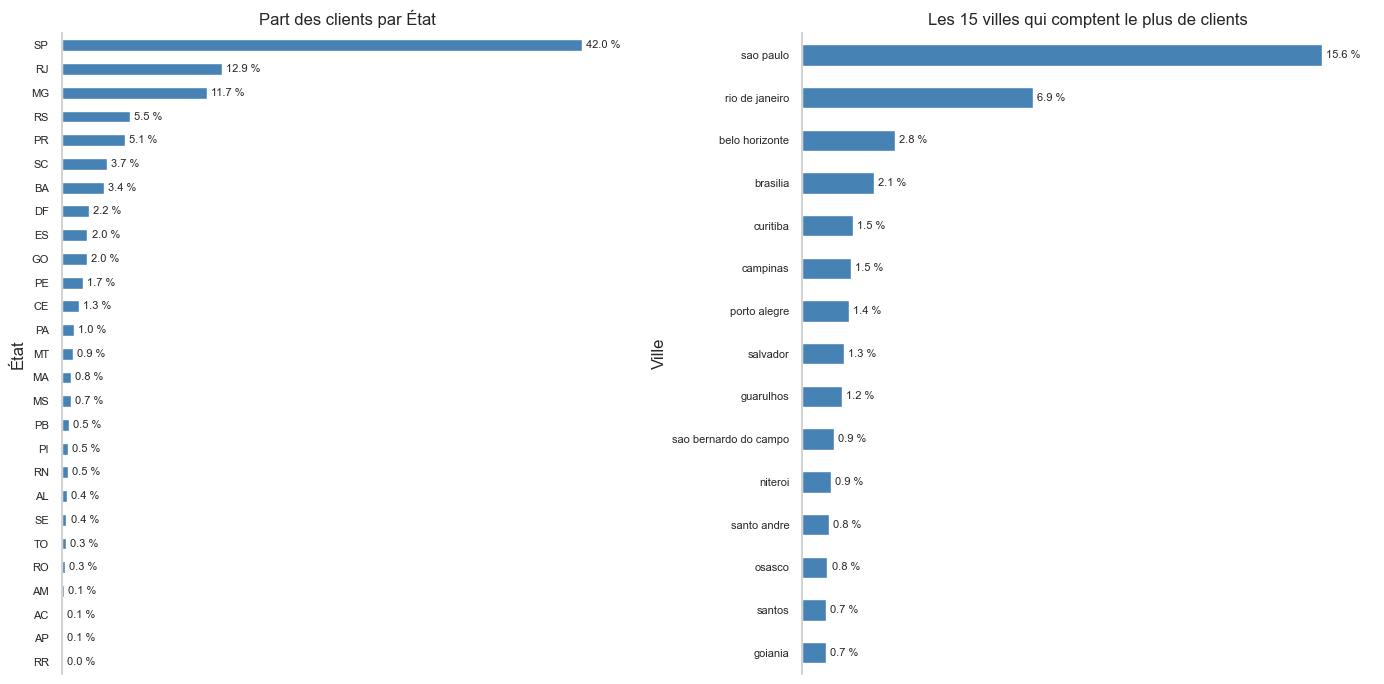

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(14, 7))

# Part des clients par État, en %
part_etats = merge_customers_loc['customer_state'].value_counts(normalize=True) * 100
part_etats.sort_values().plot.barh(color='steelblue', ax=ax[0])
ax[0].bar_label(ax[0].containers[0], fmt='%.1f %%', padding=3, fontsize=8)
ax[0].set_title('Part des clients par État')
ax[0].set_ylabel('État')
ax[0].set_xlim(0, part_etats.max() * 1.10)  # place à droite pour les pourcentages

# Les 15 villes qui comptent le plus de clients, en %
part_villes = merge_customers_loc['customer_city'].value_counts(normalize=True).head(15) * 100
part_villes.sort_values().plot.barh(color='steelblue', ax=ax[1])
ax[1].bar_label(ax[1].containers[0], fmt='%.1f %%', padding=3, fontsize=8)
ax[1].set_title('Les 15 villes qui comptent le plus de clients')
ax[1].set_ylabel('Ville')
ax[1].set_xlim(0, part_villes.max() * 1.10)  # place à droite pour les pourcentages

# Mise en forme commune : on masque l'axe des pourcentages (déjà affichés sur les barres)
for a in ax:
    a.tick_params(axis='y', labelsize=8)
    a.xaxis.set_visible(False)
    a.grid(False)
    sns.despine(ax=a, bottom=True)

plt.tight_layout()

# Sauvegarde du graphique au format PNG
fig.savefig('images/repartition_clients.png', dpi=150, bbox_inches='tight')
plt.show()

**À retenir :** les clients sont très concentrés dans le **sud-est du Brésil**. L'État de **São Paulo (SP)** regroupe à lui seul **42 %** des clients, et les trois premiers États (SP, RJ, MG) en concentrent **les deux tiers**. Côté villes, **São Paulo** (16 %) et **Rio de Janeiro** (7 %) arrivent largement en tête.

#### Localisation des clients sur la carte

In [16]:
# Bibliothèques de cartographie
from shapely.geometry import Point   # pour créer des points géographiques
import geopandas as gpd              # pandas adapté aux données géographiques

# Transformer chaque client en point GPS (longitude, latitude)
geometry = [Point(xy) for xy in zip(merge_customers_loc['geolocation_lng'],
                                    merge_customers_loc['geolocation_lat'])]

# Tableau géographique : les données clients + leur position
# EPSG:4326 = système de coordonnées GPS standard (latitude / longitude en degrés)
gdf = gpd.GeoDataFrame(merge_customers_loc, geometry=geometry, crs="EPSG:4326")

# Fond de carte : contours des pays du monde (source : Natural Earth)
world = gpd.read_file("https://naciscdn.org/naturalearth/110m/cultural/ne_110m_admin_0_countries.zip")
ax = world.plot(figsize=(14, 8), color="lightgrey", edgecolor="white")

# Clients en rouge par-dessus le fond de carte
# (petits points transparents pour voir les zones de forte concentration)
gdf.plot(ax=ax, marker='o', color='red', markersize=2, alpha=0.3)
ax.set_title("Localisation des clients d'Olist dans le monde")

# Sauvegarde de la carte au format PNG
plt.savefig('images/carte_clients.png', dpi=150, bbox_inches='tight')
plt.show()

ModuleNotFoundError: No module named 'shapely'

In [ ]:
# Clients dont les coordonnées tombent hors du Brésil
# (rectangle formé par les points extrêmes du pays : vérification approximative)
hors_bresil = merge_customers_loc[(merge_customers_loc['geolocation_lat'] > 5.3) |
                                  (merge_customers_loc['geolocation_lat'] < -33.8) |
                                  (merge_customers_loc['geolocation_lng'] < -74) |
                                  (merge_customers_loc['geolocation_lng'] > -34.7)]

print(f"Clients hors du Brésil : {len(hors_bresil)}")
hors_bresil[['customer_city', 'customer_state', 'geolocation_lat', 'geolocation_lng']]

**À retenir :** la carte confirme la concentration des clients dans le **sud-est** du Brésil, autour de São Paulo et Rio de Janeiro. Les régions du nord, plus vastes mais moins peuplées, comptent peu de clients.
Seuls **5 clients** apparaissent hors du Brésil. Leur ville et leur État sont pourtant brésiliens : ce sont donc des **erreurs de coordonnées GPS**, sans impact sur la suite de l'analyse.

### Les valeurs manquantes

In [ ]:
# Nombre et pourcentage de valeurs manquantes par colonne
manquantes = pd.DataFrame({
    'Nombre': merge_customers_loc.isnull().sum(),
    'Pourcentage (%)': (merge_customers_loc.isnull().mean() * 100).round(2)
})
manquantes[manquantes['Nombre'] > 0]

**À retenir :** seuls **278 clients (0,3 %)** n'ont pas de coordonnées GPS : leur code postal est absent du fichier de géolocalisation. Ces valeurs manquantes ne concernent que la carte et **n'ont aucun impact sur la segmentation RFM**, qui n'utilise pas la localisation. On conserve donc ces clients.

<a href="#sommaire" rev="footnote">&#8617;</a>

## Les commandes <a class="anchor" id="2"></a>

Le fichier des commandes contient une ligne par commande, avec son **statut** (livrée, annulée…) et ses **dates clés** : achat, validation, remise au transporteur, livraison au client et livraison estimée.

In [ ]:
# Copie de travail pour ne pas modifier les données d'origine
df_orders = olist_orders_dataset.copy()

print(f"Le fichier contient {df_orders.shape[0]:,} commandes et {df_orders.shape[1]} colonnes.")
df_orders.head()

### Conversion des dates

Pandas lit les dates du fichier comme du **texte**. Il faut les convertir au format **date** pour pouvoir calculer des durées (comme la récence du RFM) ou extraire le mois et l'heure d'achat.

In [ ]:
df_orders.dtypes

In [ ]:
# Colonnes contenant des dates
colonnes_dates = ['order_purchase_timestamp', 'order_approved_at',
                  'order_delivered_carrier_date', 'order_delivered_customer_date',
                  'order_estimated_delivery_date']

# Conversion du texte au format date
for col in colonnes_dates:
    df_orders[col] = pd.to_datetime(df_orders[col])

df_orders.dtypes

In [ ]:
# Période couverte par les commandes
premiere = df_orders['order_purchase_timestamp'].min()
derniere = df_orders['order_purchase_timestamp'].max()

print(f"Première commande : {premiere:%d/%m/%Y}")
print(f"Dernière commande : {derniere:%d/%m/%Y}")
print(f"Soit une période de {(derniere - premiere).days} jours (environ 2 ans)")

### Statut des commandes

In [ ]:
# Nombre et part de chaque statut de commande
statuts = pd.DataFrame({
    'Nombre': df_orders['order_status'].value_counts(),
    'Part (%)': (df_orders['order_status'].value_counts(normalize=True) * 100).round(2)
})
statuts

**À retenir :** **97 %** des commandes ont été **livrées**. Les autres sont en cours (expédiées, facturées, en préparation) ou n'ont pas abouti : **625 commandes annulées** (`canceled`) et **609 indisponibles** (`unavailable`), soit environ 1,2 % au total.

Ces commandes non abouties n'ont pas généré d'achat réel : il faudra se demander s'il faut les **exclure** du calcul du RFM.

### Évolution des commandes dans le temps

In [ ]:
dates = df_orders['order_purchase_timestamp']

fig = plt.figure(figsize=(14, 9))

# 1. Évolution du nombre de commandes mois par mois
ax1 = plt.subplot(2, 1, 1)
dates.dt.to_period('M').value_counts().sort_index().plot(marker='o', color='steelblue', ax=ax1)
ax1.set_title('Nombre de commandes par mois')
ax1.set_xlabel('')
ax1.set_ylabel('Nombre de commandes')

# 2. Part des commandes par jour de la semaine (dans l'ordre, du lundi au dimanche)
ax2 = plt.subplot(2, 2, 3)
part_jours = dates.dt.dayofweek.value_counts(normalize=True).sort_index() * 100
part_jours.index = ['Lundi', 'Mardi', 'Mercredi', 'Jeudi', 'Vendredi', 'Samedi', 'Dimanche']
part_jours.plot.bar(color='steelblue', ax=ax2)
ax2.bar_label(ax2.containers[0], fmt='%.1f %%', fontsize=8)
ax2.set_title('Part des commandes par jour de la semaine')
ax2.tick_params(axis='x', labelrotation=0)

# 3. Part des commandes par heure de la journée
ax3 = plt.subplot(2, 2, 4)
part_heures = dates.dt.hour.value_counts(normalize=True).sort_index() * 100
part_heures.plot.bar(color='steelblue', ax=ax3)
ax3.set_title('Part des commandes par heure de la journée')
ax3.set_xlabel('Heure')
ax3.set_ylabel('Part des commandes (%)')
ax3.tick_params(axis='x', labelrotation=0)

plt.tight_layout()
fig.savefig('images/commandes_dans_le_temps.png', dpi=150, bbox_inches='tight')
plt.show()

**À retenir :**
- **Une forte croissance** : le nombre de commandes passe d'environ 800 en janvier 2017 à plus de 7 000 par mois début 2018.
- **Un pic en novembre 2017** (7 544 commandes), dû au **Black Friday** : 1 176 commandes ont été passées le seul 24 novembre 2017.
- **Des données incomplètes** avant janvier 2017 et après août 2018 : septembre et octobre 2018 ne comptent que 20 commandes au total. Il faudra en tenir compte pour la date de référence de la **récence**.
- **On achète plutôt en semaine** (16 % des commandes le lundi, contre 11 % le samedi) et **en journée** : les trois quarts des commandes sont passées entre 10 h et 22 h.

### Valeurs manquantes

In [ ]:
# Nombre et pourcentage de valeurs manquantes par colonne
manquantes = pd.DataFrame({
    'Nombre': df_orders.isnull().sum(),
    'Pourcentage (%)': (df_orders.isnull().mean() * 100).round(2)
})
manquantes[manquantes['Nombre'] > 0]

In [ ]:
# Statut des commandes sans date de livraison
df_orders.loc[df_orders['order_delivered_customer_date'].isnull(), 'order_status'].value_counts()

**À retenir :** les valeurs manquantes ne concernent que les **dates de validation et de livraison**, et sont **cohérentes** : une commande annulée ou pas encore livrée n'a pas de date de livraison. Sur les 2 965 commandes sans date de livraison, seules **8 sont marquées comme livrées**.
Ces colonnes ne sont pas utilisées pour le RFM, qui ne repose que sur la **date d'achat**, complète à 100 %. On conserve donc ces valeurs manquantes.

<a href="#sommaire" rev="footnote">&#8617;</a>

## Les produits commandés <a class="anchor" id="3"></a>

Les informations sur les produits sont réparties dans **3 fichiers** : les produits de chaque commande, la description des produits et la traduction des catégories en anglais. On les étudie séparément, puis on les fusionne.

### Les produits de chaque commande (`olist_order_items_dataset`)

Chaque ligne correspond à **un produit dans une commande**. La colonne `order_item_id` indique le **rang du produit** dans la commande : une commande de 3 produits occupe 3 lignes, numérotées 1, 2 et 3. On y trouve aussi le **prix** du produit et les **frais de transport**.

In [ ]:
# Copie de travail pour ne pas modifier les données d'origine
df_order_items = olist_order_items_dataset.copy()

print(f"{df_order_items.shape[0]:,} produits commandés, répartis dans {df_order_items['order_id'].nunique():,} commandes")

In [ ]:
df_order_items.info()

### La description des produits (`olist_products_dataset`)

Chaque ligne décrit **un produit** : sa **catégorie** (en portugais), la longueur de son nom et de sa description, son nombre de photos, son poids et ses dimensions.

*Remarque : deux colonnes contiennent une faute d'orthographe d'origine (`lenght` au lieu de `length`). On garde les noms tels quels pour rester fidèle aux données.*

In [ ]:
# Copie de travail pour ne pas modifier les données d'origine
df_products = olist_products_dataset.copy()

print(f"{df_products.shape[0]:,} produits, répartis dans {df_products['product_category_name'].nunique()} catégories")
print(f"Produits sans catégorie : {df_products['product_category_name'].isnull().sum()}")

In [ ]:
df_products.info()

### La traduction des catégories (`product_category_name_translation`)

Ce fichier associe chaque catégorie en **portugais** à sa traduction en **anglais**, plus facile à interpréter.

In [ ]:
print(f"{product_category_name_translation.shape[0]} catégories traduites")

# Catégories de produits absentes du fichier de traduction
non_traduites = set(df_products['product_category_name'].dropna()) - set(product_category_name_translation['product_category_name'])
print(f"Catégories sans traduction : {non_traduites}")

**2 catégories n'ont pas de traduction.** On les ajoute au fichier de traduction **avant** la fusion, pour que tous les produits aient une catégorie en anglais.

In [ ]:
# Ajout des 2 traductions manquantes à la fin du fichier de traduction
traductions_manquantes = pd.DataFrame({
    'product_category_name': ['portateis_cozinha_e_preparadores_de_alimentos', 'pc_gamer'],
    'product_category_name_english': ['portable_kitchen_and_food_preparers', 'pc_gamer']
})
product_category_name_translation = pd.concat([product_category_name_translation, traductions_manquantes],
                                              ignore_index=True)

print(f"{product_category_name_translation.shape[0]} catégories traduites")

### Fusion des trois fichiers

On associe à chaque produit commandé sa **description**, grâce à la clé `product_id`, puis la **traduction de sa catégorie**, grâce à `product_category_name`.

In [ ]:
# 1. Produits commandés + description des produits (clé : product_id)
df_order_items_products = df_order_items.merge(df_products, on='product_id', how='left')

# 2. + traduction des catégories (clé : product_category_name)
df_order_items_products = df_order_items_products.merge(product_category_name_translation,
                                                        on='product_category_name', how='left')

# La date limite d'expédition est lue comme du texte : conversion au format date
df_order_items_products['shipping_limit_date'] = pd.to_datetime(df_order_items_products['shipping_limit_date'])

# Vérification : la fusion ne doit ni perdre ni dupliquer de lignes
print(f"Lignes avant la fusion : {df_order_items.shape[0]:,}")
print(f"Lignes après la fusion : {df_order_items_products.shape[0]:,}")
df_order_items_products.head()

In [ ]:
# Chaque ligne doit être unique pour le couple (commande, rang du produit)
print(f"Lignes en double : {df_order_items_products.duplicated(subset=['order_id', 'order_item_id']).sum()}")

# Nombre de valeurs différentes dans chaque colonne de type texte
df_order_items_products.select_dtypes(object).nunique()

**À retenir :** les **112 650 produits commandés** correspondent à **98 666 commandes**, **32 951 produits** différents et **3 095 vendeurs**, sans aucune ligne en double. Toutes les catégories ont maintenant une traduction en anglais, sauf les **610 produits sans catégorie** dans les données d'origine.

### Nombre de produits par commande

In [ ]:
# Nombre de produits dans chaque commande (une ligne = un produit)
n_produits_par_commande = df_order_items_products.groupby('order_id').size()

# Part des commandes selon leur nombre de produits
part_commandes = n_produits_par_commande.value_counts(normalize=True).sort_index() * 100

fig, ax = plt.subplots(figsize=(10, 4))
part_commandes.head(6).plot.bar(color='steelblue', ax=ax)
ax.bar_label(ax.containers[0], fmt='%.1f %%', padding=3, fontsize=8)
ax.set_title('Part des commandes selon leur nombre de produits')
ax.set_xlabel('Nombre de produits dans la commande')
ax.tick_params(axis='x', labelrotation=0)
ax.yaxis.set_visible(False)
sns.despine(ax=ax, left=True)
plt.show()

**À retenir :** environ **90 % des commandes ne contiennent qu'un seul produit**. Les commandes de plus de 3 produits sont très rares.

### Prix des produits

In [ ]:
prix = df_order_items_products['price']

# Chiffres clés (en réals brésiliens, R$)
print(f"Prix médian : {prix.median():.2f} R$")
print(f"Prix moyen  : {prix.mean():.2f} R$")
print(f"Prix minimum : {prix.min():.2f} R$ | maximum : {prix.max():,.2f} R$")

fig, ax = plt.subplots(1, 2, figsize=(14, 4))

# Histogramme limité à 500 R$ : les prix très élevés, rares, écraseraient le graphique
sns.histplot(prix[prix <= 500], bins=50, color='steelblue', ax=ax[0])
ax[0].set_title('Répartition des prix (produits jusqu\'à 500 R$)')
ax[0].set_xlabel('Prix (R$)')
ax[0].set_ylabel('Nombre de produits')

# Boîte à moustaches : met en évidence les valeurs extrêmes
sns.boxplot(x=prix, color='steelblue', ax=ax[1])
ax[1].set_title('Boîte à moustaches des prix (tous les produits)')
ax[1].set_xlabel('Prix (R$)')

plt.tight_layout()
plt.show()

Les prix les plus élevés et les plus bas, avec leur catégorie :

In [ ]:
colonnes = ['price', 'product_category_name_english']

# Les 5 produits les plus chers
display(df_order_items_products.nlargest(5, 'price')[colonnes])

# Les 5 produits les moins chers
display(df_order_items_products.nsmallest(5, 'price')[colonnes])

**À retenir :** le **prix médian est de 75 réals** : la moitié des produits coûtent moins de 75 réals. Le prix moyen (121 réals) est plus élevé, car il est tiré vers le haut par quelques produits très chers. La distribution est donc très **asymétrique**.
Les prix vont de 0,85 à 6 735 réals : ces écarts s'expliquent par la **diversité des catégories** (des accessoires de mode aux ordinateurs). Ce ne sont donc pas des erreurs, on conserve toutes les valeurs.

### Frais de transport

In [ ]:
frais = df_order_items_products['freight_value']

# Chiffres clés (en réals)
print(f"Frais médians : {frais.median():.2f} réals")
print(f"Frais moyens  : {frais.mean():.2f} réals")
print(f"Frais minimum : {frais.min():.2f} réals | maximum : {frais.max():.2f} réals")
print(f"Produits livrés gratuitement : {(frais == 0).sum()}")

fig, ax = plt.subplots(1, 2, figsize=(14, 4))

# Histogramme limité à 100 réals : les frais très élevés, rares, écraseraient le graphique
sns.histplot(frais[frais <= 100], bins=50, color='steelblue', ax=ax[0])
ax[0].set_title('Répartition des frais de transport (jusqu\'à 100 réals)')
ax[0].set_xlabel('Frais de transport (réals)')
ax[0].set_ylabel('Nombre de produits')

# Boîte à moustaches : met en évidence les valeurs extrêmes
sns.boxplot(x=frais, color='steelblue', ax=ax[1])
ax[1].set_title('Boîte à moustaches des frais de transport')
ax[1].set_xlabel('Frais de transport (réals)')

plt.tight_layout()
plt.show()

**À retenir :** les frais de transport sont de **16 réals en médiane** (20 réals en moyenne), soit environ un cinquième du prix médian d'un produit. Ils vont de 0 à 410 réals : **383 produits** ont été livrés **gratuitement**, et les frais les plus élevés concernent probablement des produits lourds ou volumineux.

### Autres caractéristiques des produits

Ces caractéristiques (description, photos, poids, dimensions) ne seront **pas utilisées pour la segmentation RFM**. On en donne seulement un résumé.

In [ ]:
# Ordre d'affichage : poids et dimensions d'abord, puis la présentation du produit
caracteristiques = ['product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm',
                    'product_photos_qty', 'product_name_lenght', 'product_description_lenght']

# Noms en français, avec l'unité
noms_caracteristiques = {
    'product_weight_g': 'Poids (g)',
    'product_length_cm': 'Longueur (cm)',
    'product_height_cm': 'Hauteur (cm)',
    'product_width_cm': 'Largeur (cm)',
    'product_photos_qty': 'Nombre de photos',
    'product_name_lenght': 'Longueur du nom (caractères)',
    'product_description_lenght': 'Longueur de la description (caractères)'
}

# Chiffres clés de chaque caractéristique
(df_order_items_products[caracteristiques]
 .describe().T[['min', '50%', 'max']]
 .rename(index=noms_caracteristiques,
         columns={'min': 'Minimum', '50%': 'Médiane', 'max': 'Maximum'}))

### Date limite d'expédition

La colonne `shipping_limit_date` indique la date limite à laquelle le vendeur doit **remettre le produit au transporteur**.

In [ ]:
date_exp = df_order_items_products['shipping_limit_date']
print(f"Dates limites d'expédition : du {date_exp.min():%d/%m/%Y} au {date_exp.max():%d/%m/%Y}")

# Dates postérieures à la dernière commande (octobre 2018) : anomalies probables
anomalies = df_order_items_products[date_exp > '2018-10-31']
print(f"Produits avec une date limite après octobre 2018 : {len(anomalies)}")
anomalies[['order_id', 'shipping_limit_date', 'price']]

**À retenir :** les dates limites d'expédition suivent logiquement les dates de commande. Seuls **4 produits** ont une date limite en **2020**, plus d'un an après la dernière commande : il s'agit vraisemblablement d'**erreurs de saisie**. Cette colonne n'étant pas utilisée pour la segmentation, ces anomalies n'ont pas d'impact sur la suite.

<a href="#sommaire" rev="footnote">&#8617;</a>

## Les paiements <a class="anchor" id="4"></a>

Chaque ligne correspond à **un paiement**. Une commande peut en avoir plusieurs, si le client a utilisé plusieurs moyens de paiement (par exemple une carte et un bon d'achat). Les principales colonnes sont :
- `payment_sequential` : le **numéro du paiement** dans la commande (1, 2, 3…) ;
- `payment_type` : le **moyen de paiement** (carte de crédit, *boleto*, bon d'achat, carte de débit) ;
- `payment_installments` : le **nombre de mensualités** choisi par le client ;
- `payment_value` : le **montant** payé, en réals.

In [ ]:
# Copie de travail pour ne pas modifier les données d'origine
df_payments = olist_order_payments_dataset.copy()

print(f"{df_payments.shape[0]:,} paiements pour {df_payments['order_id'].nunique():,} commandes")
print(f"Lignes en double : {df_payments.duplicated().sum()}")
print(f"Valeurs manquantes : {df_payments.isnull().sum().sum()}")
df_payments.head()

### Moyens de paiement et mensualités

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))

# Part de chaque moyen de paiement, en %
noms_paiements = {'credit_card': 'Carte de crédit', 'boleto': 'Boleto',
                  'voucher': "Bon d'achat", 'debit_card': 'Carte de débit', 'not_defined': 'Non défini'}
part_types = df_payments['payment_type'].map(noms_paiements).value_counts(normalize=True) * 100
part_types.sort_values().plot.barh(color='steelblue', ax=ax[0])
ax[0].bar_label(ax[0].containers[0], fmt='%.1f %%', padding=3, fontsize=8)
ax[0].set_title('Moyens de paiement')
ax[0].set_ylabel('')
ax[0].set_xlim(0, part_types.max() * 1.15)
ax[0].xaxis.set_visible(False)

# Part des paiements selon le nombre de mensualités (jusqu'à 10)
part_mensualites = df_payments['payment_installments'].value_counts(normalize=True).sort_index() * 100
part_mensualites.loc[1:10].plot.bar(color='steelblue', ax=ax[1])
ax[1].bar_label(ax[1].containers[0], fmt='%.0f %%', padding=3, fontsize=8)
ax[1].set_title('Nombre de mensualités')
ax[1].set_xlabel('Nombre de mensualités')
ax[1].tick_params(axis='x', labelrotation=0)
ax[1].yaxis.set_visible(False)

for a in ax:
    a.grid(False)
    sns.despine(ax=a, left=True, bottom=True)

plt.tight_layout()
plt.show()

# Commandes payées en plusieurs paiements
part_multi = (df_payments.groupby('order_id').size() > 1).mean() * 100
print(f"Commandes réglées avec plusieurs paiements : {part_multi:.1f} %")

**À retenir :** les clients paient surtout par **carte de crédit** (74 %), puis par **boleto** (19 %), un bordereau de paiement brésilien très utilisé par les personnes sans carte bancaire. La moitié des paiements se font **en une seule fois**, mais le paiement en plusieurs mensualités est courant au Brésil, jusqu'à 10 fois. Enfin, **97 % des commandes** sont réglées en un seul paiement.

### Montant des paiements

In [ ]:
montant = df_payments['payment_value']

# Chiffres clés (en réals)
print(f"Montant médian : {montant.median():.2f} réals")
print(f"Montant moyen  : {montant.mean():.2f} réals")
print(f"Montant maximum : {montant.max():,.2f} réals")
print(f"Paiements de 0 réal : {(montant == 0).sum()}")

fig, ax = plt.subplots(1, 2, figsize=(14, 4))

# Histogramme limité à 1 000 réals : les montants très élevés, rares, écraseraient le graphique
sns.histplot(montant[montant <= 1000], bins=50, color='steelblue', ax=ax[0])
ax[0].set_title('Répartition des montants payés (jusqu\'à 1 000 réals)')
ax[0].set_xlabel('Montant payé (réals)')
ax[0].set_ylabel('Nombre de paiements')

# Boîte à moustaches : met en évidence les valeurs extrêmes
sns.boxplot(x=montant, color='steelblue', ax=ax[1])
ax[1].set_title('Boîte à moustaches des montants payés')
ax[1].set_xlabel('Montant payé (réals)')

plt.tight_layout()
plt.show()

In [ ]:
# Détail de la commande au paiement le plus élevé
commande_max = df_payments.loc[montant.idxmax(), 'order_id']
df_order_items_products.loc[df_order_items_products['order_id'] == commande_max,
                            ['order_item_id', 'product_category_name_english', 'price', 'freight_value']]

**À retenir :** le **montant médian d'un paiement est de 100 réals** (154 réals en moyenne). Comme pour le prix, la distribution est très **asymétrique**, avec quelques montants très élevés.
Le paiement le plus élevé (13 664 réals) correspond à **8 téléphones fixes identiques** achetés dans une même commande, probablement par une entreprise : ce n'est donc pas une erreur. On conserve toutes les valeurs, car ces montants serviront à calculer le **M (Montant)** du RFM.

<a href="#sommaire" rev="footnote">&#8617;</a>

## Les avis des clients <a class="anchor" id="5"></a>

Après sa livraison, le client peut évaluer sa commande. Chaque ligne correspond à **un avis**, avec :
- une **note** de 1 (très insatisfait) à 5 (très satisfait), `review_score` ;
- un **titre** et un **commentaire**, facultatifs ;
- la date d'envoi du questionnaire et la date de réponse du client.

In [ ]:
# Copie de travail pour ne pas modifier les données d'origine
df_reviews = olist_order_reviews_dataset.copy()

# Conversion des dates (lues comme du texte)
for col in ['review_creation_date', 'review_answer_timestamp']:
    df_reviews[col] = pd.to_datetime(df_reviews[col])

print(f"{df_reviews.shape[0]:,} avis")
print(f"Commandes évaluées : {df_reviews['order_id'].nunique():,}")
print(f"Identifiants d'avis différents : {df_reviews['review_id'].nunique():,}")
df_reviews.head()

### Avis rattachés à plusieurs commandes

Certains avis (même identifiant, même note, même commentaire) apparaissent pour **plusieurs commandes**. Il ne s'agit pas d'erreurs : un client qui passe plusieurs commandes en même temps reçoit **un seul questionnaire**, et sa réponse s'applique à chacune de ses commandes.

In [ ]:
# Avis rattachés à plusieurs commandes
avis_multiples = df_reviews[df_reviews.duplicated(subset='review_id', keep=False)]
print(f"Avis rattachés à plusieurs commandes : {avis_multiples['review_id'].nunique():,}")
print(f"Commandes concernées : {avis_multiples['order_id'].nunique():,}")

# Vraies lignes en double : même avis ET même commande
print(f"Lignes en double (même avis, même commande) : {df_reviews.duplicated(subset=['review_id', 'order_id']).sum()}")

# Exemple : un avis et ses commandes
avis_multiples.sort_values('review_id')[['review_id', 'order_id', 'review_score']].head(4)

**Décision :** on **conserve tous ces avis**, pour que chaque commande garde sa note. Les supprimer retirerait la note de certaines commandes, qui disparaîtraient ensuite de la segmentation RFM.

### Satisfaction des clients

In [ ]:
# Part des avis pour chaque note, en %
part_notes = df_reviews['review_score'].value_counts(normalize=True).sort_index() * 100

fig, ax = plt.subplots(figsize=(8, 4))
part_notes.plot.bar(color='steelblue', ax=ax)
ax.bar_label(ax.containers[0], fmt='%.1f %%', padding=3, fontsize=9)
ax.set_title('Répartition des notes données par les clients')
ax.set_xlabel('Note attribuée (de 1 à 5)')
ax.tick_params(axis='x', labelrotation=0)
ax.yaxis.set_visible(False)
ax.grid(False)
sns.despine(ax=ax, left=True)
fig.savefig('images/notes_clients.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"Note moyenne : {df_reviews['review_score'].mean():.2f} / 5")

**À retenir :** les clients sont **globalement satisfaits** : plus de la moitié donnent la note maximale (5/5), et la note moyenne est d'environ 4,1 sur 5.
Les avis sont toutefois **polarisés** : environ **12 % des clients donnent la note minimale (1/5)**, bien plus que les notes 2 ou 3. Les clients mécontents le sont souvent fortement.

### Valeurs manquantes

In [ ]:
# Nombre et pourcentage de valeurs manquantes par colonne
manquantes = pd.DataFrame({
    'Nombre': df_reviews.isnull().sum(),
    'Pourcentage (%)': (df_reviews.isnull().mean() * 100).round(1)
})
manquantes[manquantes['Nombre'] > 0]

**À retenir :** seuls le **titre** (absent dans environ 88 % des avis) et le **commentaire** (absent dans environ 59 %) ont des valeurs manquantes. C'est normal : ces champs sont **facultatifs**, contrairement à la note.
Ces textes en portugais ne sont pas utilisés pour la segmentation. Seule la **note**, complète à 100 %, pourra servir à enrichir le RFM.

<a href="#sommaire" rev="footnote">&#8617;</a>

## Les vendeurs <a class="anchor" id="6"></a>

Olist est une marketplace : les produits sont vendus par des **vendeurs indépendants**. Ce fichier indique leur localisation (code postal, ville, État).

In [ ]:
# Copie de travail pour ne pas modifier les données d'origine
df_sellers = olist_sellers_dataset.copy()

print(f"{df_sellers.shape[0]:,} vendeurs")
print(f"Villes différentes : {df_sellers['seller_city'].nunique()}")
print(f"États différents : {df_sellers['seller_state'].nunique()} (sur 27)")

In [ ]:
# Part des vendeurs par État, en %
part_vendeurs = df_sellers['seller_state'].value_counts(normalize=True) * 100

fig, ax = plt.subplots(figsize=(8, 6))
part_vendeurs.sort_values().plot.barh(color='steelblue', ax=ax)
ax.bar_label(ax.containers[0], fmt='%.1f %%', padding=3, fontsize=8)
ax.set_title('Part des vendeurs par État')
ax.set_ylabel('État')
ax.set_xlim(0, part_vendeurs.max() * 1.15)
ax.tick_params(axis='y', labelsize=8)
ax.xaxis.set_visible(False)
ax.grid(False)
sns.despine(ax=ax, bottom=True)
plt.tight_layout()
plt.show()

**À retenir :** les **3 095 vendeurs** sont répartis dans **23 États** sur 27. Ils sont encore plus concentrés que les clients : **60 %** d'entre eux sont installés dans l'**État de São Paulo** (contre 42 % des clients), suivis du Paraná (11 %) et du Minas Gerais (8 %).
Les vendeurs ne sont pas concernés par la segmentation des clients ; cette section complète simplement la vue d'ensemble des données.

<a href="#sommaire" rev="footnote">&#8617;</a>

## Construction du fichier RFM <a class="anchor" id="7"></a>

La méthode **RFM** décrit chaque client par trois indicateurs :
- **R – Récence** : le nombre de jours depuis sa dernière commande. *Plus elle est faible, plus le client est actif.*
- **F – Fréquence** : son nombre de commandes. *Plus elle est élevée, plus le client est fidèle.*
- **M – Montant** : le total qu'il a dépensé. *Plus il est élevé, plus le client a de la valeur.*

Ces trois indicateurs serviront de base à la segmentation, dans le notebook 2. On y ajoute deux informations utilisées dans certains essais : la **note moyenne** et le **nombre de produits** achetés.

### 1. Sélection des commandes abouties

Les commandes **annulées** (`canceled`) et **indisponibles** (`unavailable`) n'ont pas donné lieu à un achat réel : on les exclut du calcul.

In [ ]:
# On exclut les commandes qui n'ont pas abouti à un achat
statuts_exclus = ['canceled', 'unavailable']
commandes = df_orders[~df_orders['order_status'].isin(statuts_exclus)]

print(f"Commandes au départ : {df_orders.shape[0]:,}")
print(f"Commandes exclues   : {df_orders.shape[0] - commandes.shape[0]:,}")
print(f"Commandes conservées : {commandes.shape[0]:,}")

### 2. Montant et nombre de produits par commande

Chaque information est calculée à partir du fichier adapté :
- le **montant** de la commande : la somme de ses paiements ;
- le **nombre de produits** : le nombre de lignes de la commande dans le fichier des produits commandés (une ligne = un produit).

In [ ]:
# Montant total payé par commande (somme de ses paiements)
montants = df_payments.groupby('order_id').agg(montant_command=('payment_value', 'sum')).reset_index()

# Nombre de produits par commande (une ligne = un produit)
n_produits = df_order_items.groupby('order_id').size().reset_index(name='n_produits')

print(f"Commandes avec un montant : {montants.shape[0]:,}")
print(f"Commandes avec des produits : {n_produits.shape[0]:,}")

### 3. Note par commande

Une commande peut avoir reçu **plusieurs avis**. On calcule donc sa **note moyenne**, pour avoir une seule note par commande.

In [ ]:
# Note moyenne de chaque commande
notes = df_reviews.groupby('order_id').agg(review_score=('review_score', 'mean')).reset_index()

print(f"Commandes avec une note : {notes.shape[0]:,}")
print(f"Commandes avec plusieurs avis : {(df_reviews.groupby('order_id').size() > 1).sum():,}")
notes.head()

### 4. Une ligne par commande : fusion des informations

On réunit, pour chaque commande conservée, le client, la date d'achat, le montant, le nombre de produits et la note. Les fusions `left` garantissent qu'**aucune commande n'est perdue**, même sans avis.

In [ ]:
# Clients + commandes conservées (un client sans commande aboutie n'est pas segmenté)
data = df_customers.merge(commandes, on='customer_id', how='inner')

# + montant, nombre de produits et note : fusions "left" pour ne perdre aucune commande
data = (data
        .merge(montants, on='order_id', how='left')
        .merge(n_produits, on='order_id', how='left')
        .merge(notes, on='order_id', how='left'))

print(f"Commandes : {data.shape[0]:,}")
print("Valeurs manquantes :")
print(data[['montant_command', 'n_produits', 'review_score']].isnull().sum())

**Traitement des valeurs manquantes :**
- **Montant manquant** : la commande n'a aucun paiement enregistré. Sans montant, elle ne peut pas entrer dans le calcul du M : on la **supprime**.
- **Nombre de produits manquant** : la commande n'a aucun produit enregistré. On met **0**, pour ne pas perdre la commande.
- **Note manquante** : le client n'a pas donné d'avis. On la remplace par la **note médiane**, peu sensible aux valeurs extrêmes. Ces cas étant rares, l'impact sur l'analyse est négligeable.

In [ ]:
# Commandes sans montant : supprimées
data = data.dropna(subset=['montant_command'])

# Commandes sans produit enregistré : 0 produit
data['n_produits'] = data['n_produits'].fillna(0).astype(int)

# Commandes sans avis : note médiane
note_mediane = data['review_score'].median()
data['review_score'] = data['review_score'].fillna(note_mediane)

print(f"Note médiane utilisée : {note_mediane}")
print(f"Commandes : {data.shape[0]:,}")
print(f"Clients uniques : {data['customer_unique_id'].nunique():,}")
print(f"Valeurs manquantes restantes : {data[['montant_command', 'n_produits', 'review_score']].isnull().sum().sum()}")

### 5. Calcul du RFM de chaque client

La **récence** est calculée par rapport à une **date de référence** : le lendemain de la dernière commande conservée (le 04/09/2018), comme si l'analyse était réalisée à cette date. On regroupe ensuite les commandes **par client** (`customer_unique_id`).

In [ ]:
from datetime import timedelta

# Date de référence : le lendemain de la dernière commande
NOW = data['order_purchase_timestamp'].max() + timedelta(days=1)
print(f"Date de référence : {NOW:%d/%m/%Y}")

# Nombre de jours entre chaque commande et la date de référence
data['DaysSinceOrder'] = (NOW - data['order_purchase_timestamp']).dt.days

# Indicateurs RFM par client
rfm = data.groupby('customer_unique_id').agg(
    Recency=('DaysSinceOrder', 'min'),      # jours depuis la dernière commande
    Frequency=('order_id', 'nunique'),      # nombre de commandes différentes
    Monetary=('montant_command', 'sum')     # total dépensé
).reset_index()

print(f"{rfm.shape[0]:,} clients")
rfm.head()

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))

# Récence
sns.histplot(rfm['Recency'], bins=50, color='steelblue', ax=ax[0])
ax[0].set_title('Récence')
ax[0].set_xlabel('Jours depuis la dernière commande')
ax[0].set_ylabel('Nombre de clients')

# Fréquence (en %)
part_freq = rfm['Frequency'].value_counts(normalize=True).sort_index().head(4) * 100
part_freq.plot.bar(color='steelblue', ax=ax[1])
ax[1].bar_label(ax[1].containers[0], fmt='%.1f %%', padding=3, fontsize=8)
ax[1].set_title('Fréquence')
ax[1].set_xlabel('Nombre de commandes')
ax[1].tick_params(axis='x', labelrotation=0)
ax[1].yaxis.set_visible(False)

# Montant (limité à 1 000 réals pour la lisibilité)
sns.histplot(rfm.loc[rfm['Monetary'] <= 1000, 'Monetary'], bins=50, color='steelblue', ax=ax[2])
ax[2].set_title('Montant (clients jusqu\'à 1 000 réals)')
ax[2].set_xlabel('Total dépensé (réals)')
ax[2].set_ylabel('Nombre de clients')

plt.tight_layout()
fig.savefig('images/distribution_rfm.png', dpi=150, bbox_inches='tight')
plt.show()

print(rfm[['Recency', 'Frequency', 'Monetary']].describe().round(1))

**À retenir :**
- **Récence** : la moitié des clients ont commandé il y a moins de **224 jours** (environ 7 mois).
- **Fréquence** : **97 % des clients n'ont passé qu'une seule commande**. C'est le constat le plus important du projet : Olist peine à **fidéliser** ses clients. La fréquence varie donc très peu d'un client à l'autre.
- **Montant** : un client dépense **108 réals en médiane** (166 en moyenne). La distribution est très asymétrique, avec quelques clients qui dépensent beaucoup.

#### Transformation logarithmique

L'algorithme **K-Means**, utilisé dans le notebook 2, regroupe les clients selon leurs **distances**. Avec des variables très asymétriques comme le montant, quelques valeurs extrêmes domineraient ces distances.
On applique donc un **logarithme**, qui réduit l'écart entre les grandes valeurs et rend les distributions plus équilibrées. Toutes les valeurs étant supérieures ou égales à 1, le logarithme peut être appliqué directement.

In [ ]:
# Logarithme des trois indicateurs (toutes les valeurs sont >= 1)
rfm_log = np.log(rfm[['Recency', 'Frequency', 'Monetary']])

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
titres = {'Recency': 'log(Récence)', 'Frequency': 'log(Fréquence)', 'Monetary': 'log(Montant)'}
for a, col in zip(ax, titres):
    sns.histplot(rfm_log[col], bins=50, color='steelblue', ax=a)
    a.set_title(titres[col])
    a.set_xlabel('')
    a.set_ylabel('Nombre de clients')
plt.tight_layout()
plt.show()

**À retenir :** après transformation, le **montant** suit une distribution beaucoup plus symétrique, en forme de cloche. La **fréquence**, elle, reste presque constante, puisque 97 % des clients ont une seule commande.

### 6. Enregistrement des résultats

On enregistre deux fichiers dans le dossier `data/`, qui seront lus par les notebooks 2 et 3 :
- `data_commandes.csv` : une ligne par commande (client, date, montant, nombre de produits, note) ;
- `rfm.csv` : une ligne par client, avec ses indicateurs RFM.

In [ ]:
# Une ligne par commande : utilisée pour les essais (note, produits) et la simulation de maintenance
colonnes_data = ['customer_unique_id', 'order_id', 'order_purchase_timestamp',
                 'montant_command', 'n_produits', 'review_score']
data[colonnes_data].to_csv('data/data_commandes.csv', index=False)

# Une ligne par client : les indicateurs RFM
rfm.to_csv('data/rfm.csv', index=False)

print(f"data_commandes.csv : {data.shape[0]:,} commandes enregistrées")
print(f"rfm.csv : {rfm.shape[0]:,} clients enregistrés")

<a href="#sommaire" rev="footnote">&#8617;</a>

**Ce qui a été préparé pour la segmentation :**
- Les commandes **annulées et indisponibles ont été exclues**, car elles ne correspondent pas à un achat réel.
- Chaque client est maintenant décrit par **trois chiffres**, appelés indicateurs **RFM** :
  - **Récence** : depuis combien de jours il n'a pas commandé ;
  - **Fréquence** : combien de commandes il a passées ;
  - **Montant** : combien il a dépensé au total.
  

- Ces trois chiffres ont été **transformés en logarithme**, pour que les clients qui dépensent énormément ne faussent pas la segmentation.

<a href="#sommaire" rev="footnote">&#8617;</a>